# Recorded LinkedIn applications: source-audited reanalysis

This notebook reviews the completed run and independently checks its saved
out-of-fold predictions. Running all cells does **not** repeat model fitting,
download data, or change the saved analysis results. Plotting cells are editable.

## Summary

The original Kaggle v13 CSV contains **123,849 postings**, each with a unique
`job_id`. The common analysis population contains **23,319 postings** with
observed valid application counts and views. Missing applications are never
treated as zero. Every observed application count in this source is positive,
so this is a conditional analysis of visible counts, not an unbiased analysis
of all postings or a measure of completed applications.

The tables below are reconciled with the saved OOF predictions before their
performance comparison is displayed. Original data and large fitted objects
are excluded from the public repository; the source fingerprint and download
instructions are retained.

## Context and methods

The primary Poisson, L1 Poisson and XGBoost models use the same five outer
folds. They estimate the relationship with `log1p(views)` as a predictor;
the primary offset is zero. Vocabulary, SVD, salary cutoffs and rare-category
mappings are learned from training rows. L1 strength and boosting rounds are
selected in an inner training/validation split.

### Key assumptions and limits

- Observed-count selection differs substantially by application flow.
- Views and applications are contemporaneous snapshot measures. This does
  not establish performance before a posting accumulates views.
- Expiry is a planned/end date, not a scrape timestamp or observed duration.
  Fixed reach and historical end-window offsets are sensitivities only.
- Random posting-level folds do not test a future period or unseen employers.
- Full-sample count ratios are descriptive conditional associations; their
  robust intervals do not establish causal effects or correct selection bias.

See [source provenance](../docs/DATA_SOURCE.md),
[corrections to the old analysis](../docs/CORRECTIONS.md), and
[configuration](../config.json).

### 1. Locate the repository and load the completed results
Run from the repository root or its `notebooks` directory. No personal path
is required. Install the package with the `notebook` extra before executing.

In [1]:
from pathlib import Path
import importlib.metadata
import json
import math
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import FixedLocator, FuncFormatter, NullFormatter
from IPython.display import display, Markdown
get_ipython().run_line_magic('matplotlib', 'inline')

candidates = [Path.cwd(), *Path.cwd().parents]
ROOT = next((p for p in candidates if (p / 'pyproject.toml').is_file()
             and (p / 'src' / 'linkedin_analytics').is_dir()), None)
if ROOT is None:
    raise RuntimeError('Run this notebook from the repository or notebooks directory.')
sys.path.insert(0, str(ROOT / 'src'))
RESULTS = ROOT / 'results'
from linkedin_analytics.validation import verify_results

def read_json(filename):
    return json.loads((RESULTS / filename).read_text(encoding='utf-8'))

audit = read_json('data_audit.json')
cv_run = read_json('cv_run_summary.json')
metadata = read_json('run_metadata.json')
summary = pd.read_csv(RESULTS / 'cv_summary.csv')
oof = pd.read_csv(RESULTS / 'cv_oof_predictions.csv', dtype={'row_id': str})
coefficients = pd.read_csv(RESULTS / 'poisson_coefficients.csv')
importance = pd.read_csv(RESULTS / 'xgb_feature_importance.csv')
PRIMARY = ['poisson', 'lasso_poisson', 'xgboost']
LABELS = {'constant_mean': 'Training mean', 'constant_exposure': 'Fixed count / view',
          'poisson': 'Poisson GLM', 'lasso_poisson': 'L1 Poisson', 'xgboost': 'XGBoost',
          'poisson_no_svd': 'Poisson: no SVD', 'poisson_views_offset': 'Fixed views offset',
          'poisson_legacy_offset': 'Historical window offset',
          'poisson_legacy_matched_learned': 'Learned views: matched window sample'}
COLORS = {'poisson': '#3566a6', 'lasso_poisson': '#159085', 'xgboost': '#df8850'}
plt.rcParams.update({'font.family': 'DejaVu Sans', 'font.size': 11,
                     'axes.spines.top': False, 'axes.spines.right': False,
                     'figure.dpi': 120, 'axes.titleweight': 'bold'})
pd.set_option('display.max_colwidth', 80)
display(pd.DataFrame([{
    'source': 'Kaggle: arshkon/linkedin-job-postings, version 13',
    'source_rows': audit['raw_rows'], 'analysis_rows': len(oof),
    'outer_folds': cv_run['config']['n_splits'], 'seed': cv_run['config']['seed'],
    'source_hash_matches': audit['matches_original_v13_fingerprint'],
}]))

,source,source_rows,analysis_rows,outer_folds,seed,source_hash_matches
0,"Kaggle: arshkon/linkedin-job-postings, version 13",123849,23319,5,20251201,True


### 2. Independently reconcile the saved evidence
This check uses scalar arithmetic separate from the modeling implementation,
checks global and fold-level metrics, and checks ID coverage and fold alignment.
A successful receipt verifies saved arithmetic, not causal validity.

In [2]:
validation = verify_results(RESULTS)
assert audit['raw_dataset_sha256'] == 'de33f27c8d1b226014e0cede003404e9b0acb66db718671fda9b3e3538eca6ea'
assert audit['matches_original_v13_fingerprint'] and validation['n_rows'] == len(oof)
display(pd.DataFrame([{
    'validation': validation['status'], 'rows': validation['n_rows'],
    'folds': validation['n_folds'], 'models': validation['n_models'],
    'relative_tolerance': validation['rtol'], 'absolute_tolerance': validation['atol'],
}]))
best = summary[summary.model.isin(PRIMARY)].sort_values('mean_poisson_deviance').iloc[0]
display(Markdown(
    f"**Observed result:** {LABELS[best.model]} has the lowest pooled Poisson deviance "
    f"among the three primary models ({best.mean_poisson_deviance:.3f}); "
    f"its MAE is {best.mae:.3f} and RMSE is {best.rmse:.3f}. "
    "This is a point comparison on the common conditional population, not a significance test."
))

,validation,rows,folds,models,relative_tolerance,absolute_tolerance
0,passed,23319,5,9,1.000000e-09,1.000000e-08


**Observed result:** XGBoost has the lowest pooled Poisson deviance among the three primary models (3.026); its MAE is 4.106 and RMSE is 15.530. This is a point comparison on the common conditional population, not a significance test.

## Data

### 3. Inspect the exclusion flow and source fingerprint
The edited historical working CSV had broken column boundaries and lost the
primary key. The recovered UTF-8 ZIP member is the only canonical source here.
The 100,529 missing targets are excluded, not recoded; one additional observed
target has missing views. No row is removed just for an unknown category.

In [3]:
display(pd.DataFrame(audit['exclusion_flow']).rename(columns={'stage': 'Selection stage', 'rows': 'Postings'}))
display(pd.DataFrame([{
    'raw_csv_sha256': audit['raw_dataset_sha256'],
    'unique_source_job_ids': audit['raw_unique_valid_job_ids'],
    'duplicate_source_ids': audit['raw_duplicate_job_id_extra_rows'],
    'source_has_scrape_time': audit['has_scrape_timestamp'],
    'observed_target_zeros': audit['observed_applies_zero'],
    'observed_target_missing_views': audit['observed_applies_missing_or_invalid_views'],
}]).T.rename(columns={0: 'Value'}))

,Selection stage,Postings
0,raw_source,123849
1,valid_observed_application_count,23320
2,valid_identifier_before_deduplication,23320
3,unique_observed_count_records,23320
4,common_valid_views_cohort,23319


,Value
raw_csv_sha256,de33f27c8d1b226014e0cede003404e9b0acb66db718671fda9b3e3538eca6ea
unique_source_job_ids,123849
duplicate_source_ids,0
source_has_scrape_time,False
observed_target_zeros,0
observed_target_missing_views,1


### 4. Target availability differs across application flows
Percentages use **all raw postings within each flow** as their denominator.
The one-row `UnknownApply` category is retained in the table and omitted from
the chart so that its 100% availability does not look like a stable estimate.

,raw_rows,observed_applies,observed_percent
ComplexOnsiteApply,31049.0,11638.0,37.483
OffsiteApply,84607.0,9734.0,11.505
SimpleOnsiteApply,8192.0,1947.0,23.767
UnknownApply,1.0,1.0,100.000


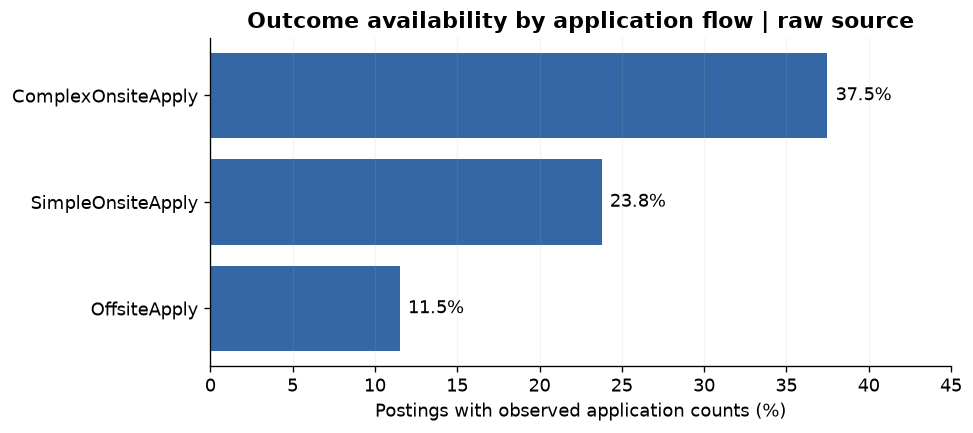

In [4]:
availability = pd.DataFrame(audit['applies_observability_by_application_type']).T
availability['observed_percent'] = 100 * availability['observed_fraction']
display(availability[['raw_rows', 'observed_applies', 'observed_percent']].round(3))
major = availability.loc[availability.raw_rows.ge(100)].sort_values('observed_percent')
fig, ax = plt.subplots(figsize=(8, 3.5), layout='constrained')
bars = ax.barh(major.index, major.observed_percent, color='#3566a6')
ax.bar_label(bars, labels=[f'{p:.1f}%' for p in major.observed_percent], padding=5)
ax.set(xlim=(0, 45), xlabel='Postings with observed application counts (%)',
       title='Outcome availability by application flow | raw source')
ax.grid(axis='x', alpha=.15)
plt.show()

### 5. Inspect the selected count distribution
The absence of observed zeros is a source/selection limitation. It does not
establish that every posting received an application. Log axes reveal the
long tail without discarding large counts.

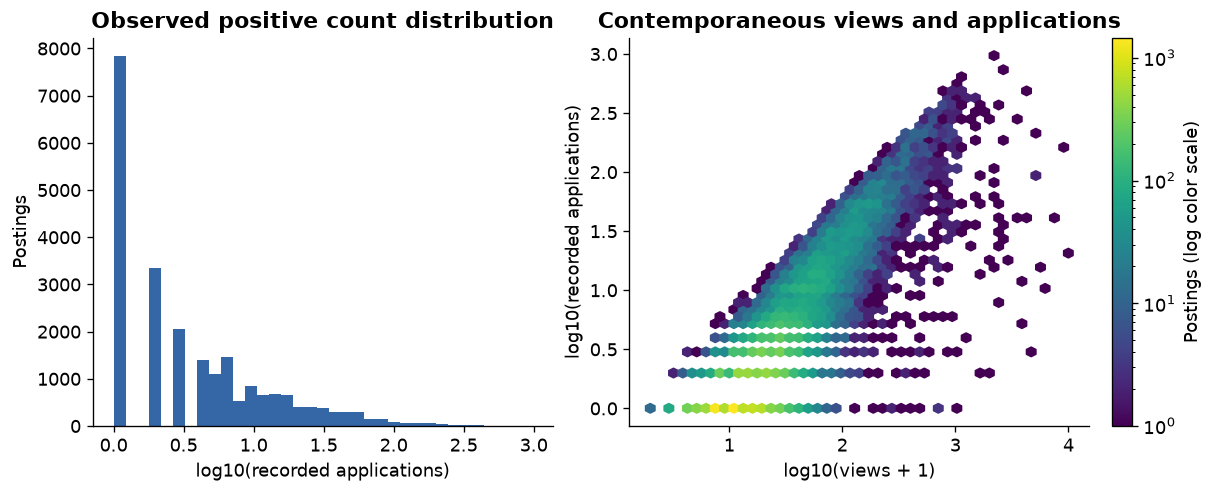

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4), layout='constrained')
axes[0].hist(np.log10(oof.applies), bins=35, color='#3566a6')
axes[0].set(xlabel='log10(recorded applications)', ylabel='Postings',
            title='Observed positive count distribution')
density = axes[1].hexbin(np.log10(oof.views + 1), np.log10(oof.applies),
                         gridsize=45, bins='log', mincnt=1, cmap='viridis')
axes[1].set(xlabel='log10(views + 1)', ylabel='log10(recorded applications)',
            title='Contemporaneous views and applications')
fig.colorbar(density, ax=axes[1], label='Postings (log color scale)')
plt.show()

## Results

### 6. Compare pooled held-out metrics on identical observations
Lower values are better. Each posting contributes one outer-fold prediction.
Different metrics emphasize different errors; these are not confidence
intervals for a model ranking. Sensitivities are identified separately below.

,n,mae,rmse,mean_poisson_deviance
model,,,,
constant_mean,23319,12.2877,29.0480,25.6812
constant_exposure,23319,6.3257,33.1910,5.9311
poisson,23319,4.9874,23.0041,4.0179
lasso_poisson,23319,4.9739,22.9059,3.9929
xgboost,23319,4.1061,15.5301,3.0261


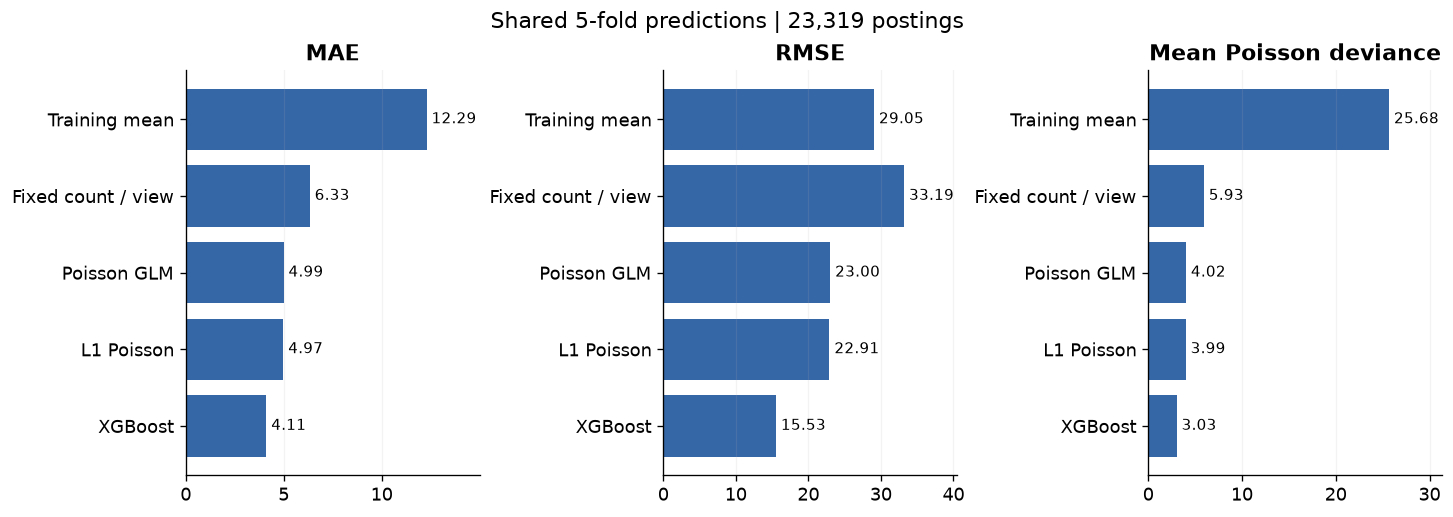

In [6]:
shown_models = ['constant_mean', 'constant_exposure', *PRIMARY]
primary_table = summary.set_index('model').loc[shown_models]
display(primary_table[['n', 'mae', 'rmse', 'mean_poisson_deviance']].round(4))
fig, axes = plt.subplots(1, 3, figsize=(12, 4.2), layout='constrained')
for ax, metric, title in zip(axes, ['mae', 'rmse', 'mean_poisson_deviance'],
                             ['MAE', 'RMSE', 'Mean Poisson deviance']):
    bars = ax.barh([LABELS[m] for m in shown_models], primary_table[metric], color='#3566a6')
    ax.bar_label(bars, fmt='%.2f', padding=3, fontsize=9)
    ax.set_xlim(0, float(primary_table[metric].max()) * 1.22)
    ax.invert_yaxis()
    ax.set_title(title)
    ax.grid(axis='x', alpha=.15)
fig.suptitle(f"Shared {cv_run['config']['n_splits']}-fold predictions | {len(oof):,} postings")
plt.show()

### 7. Recompute calibration by predicted-count decile
Within each model, postings are ranked by held-out prediction and divided into
ten equally sized groups. The diagonal marks equal predicted and recorded
mean counts. Calibration here remains conditional on a visible positive target.

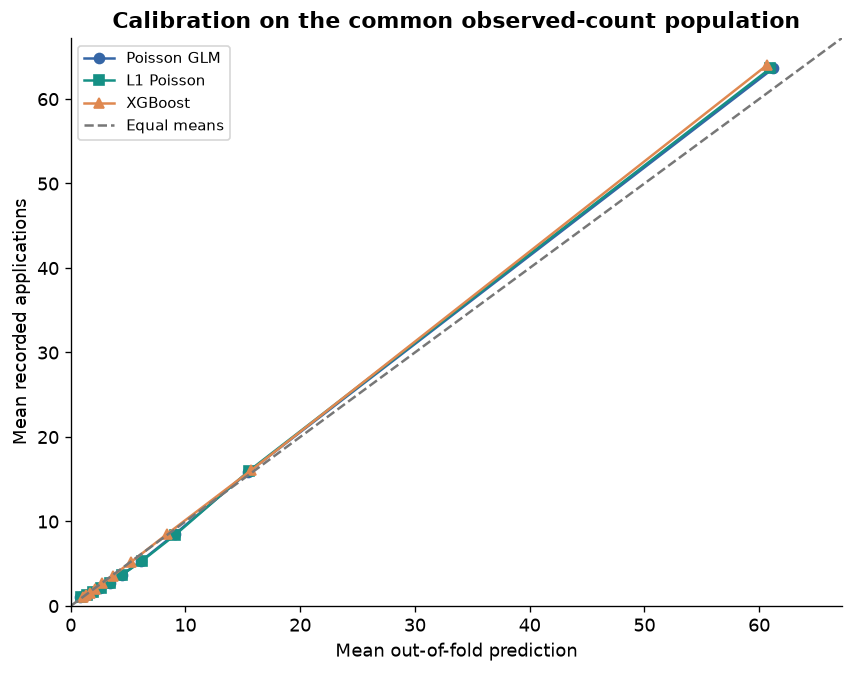

All 30 calibration groups agree with the saved chart data.


In [7]:
calibration_tables = []
fig, ax = plt.subplots(figsize=(7, 5.5), layout='constrained')
for model, marker in zip(PRIMARY, ['o', 's', '^']):
    prediction = oof['pred_' + model]
    groups = pd.qcut(prediction.rank(method='first'), 10, labels=False)
    table = pd.DataFrame({'prediction': prediction, 'outcome': oof.applies, 'decile': groups}).groupby('decile').agg(
        predicted_mean=('prediction', 'mean'), observed_mean=('outcome', 'mean'), n=('outcome', 'size')).reset_index()
    table['model'] = model
    calibration_tables.append(table)
    ax.plot(table.predicted_mean, table.observed_mean, marker=marker,
            color=COLORS[model], label=LABELS[model])
calibration = pd.concat(calibration_tables, ignore_index=True)
bound = 1.05 * max(calibration.predicted_mean.max(), calibration.observed_mean.max())
ax.plot([0, bound], [0, bound], '--', color='#777777', label='Equal means')
ax.set(xlim=(0, bound), ylim=(0, bound), xlabel='Mean out-of-fold prediction',
       ylabel='Mean recorded applications', title='Calibration on the common observed-count population')
ax.legend(fontsize=9)
plt.show()
saved_calibration = pd.read_csv(RESULTS / 'calibration_deciles.csv')
comparison = calibration.merge(saved_calibration, on=['model', 'decile'], suffixes=('_notebook', '_saved'), validate='one_to_one')
for column in ['predicted_mean', 'observed_mean', 'n']:
    np.testing.assert_allclose(comparison[column + '_notebook'], comparison[column + '_saved'], rtol=1e-10, atol=1e-9)
print('All 30 calibration groups agree with the saved chart data.')

### 8. Inspect sensitivity comparisons
`poisson_no_svd` removes description SVD terms. `poisson_views_offset` fixes
the reach-proxy coefficient to one. The historical-window pair uses identical
eligible rows; neither version treats expiry as a known observation cutoff.
These alternatives do not repair nonrandom target availability.

In [8]:
sensitivity = summary.loc[~summary.model.isin(['constant_mean', 'constant_exposure', *PRIMARY])].copy()
sensitivity['Interpretation'] = sensitivity.model.map(LABELS)
display(sensitivity[['Interpretation', 'n', 'mae', 'rmse', 'mean_poisson_deviance']].round(4))

,Interpretation,n,mae,rmse,mean_poisson_deviance
5,Poisson: no SVD,23319,5.1101,24.0045,4.1748
6,Fixed views offset,23319,4.9845,26.1914,4.1191
7,Historical window offset,23319,6.0829,29.7316,6.0249
8,Learned views: matched window sample,23319,4.9874,23.0041,4.0179


### 9. Separate descriptive associations from held-out performance
The following features are selected by name, not by p-value. Ratios compare
categories with the saved reference levels or use the numeric unit shown in
the coefficient table. Their 95% intervals are company-cluster robust when
that covariance method is recorded. They do not represent causal effects.
The `UnknownApply` singleton remains in the complete coefficient table but is
omitted from the figure; a one-posting category cannot support a stable
substantive interpretation.

,feature,irr,ci_lower,ci_upper,unit,covariance_type
1,application_type__ComplexOnsiteApply,1.3239,1.2126,1.4454,ComplexOnsiteApply vs OffsiteApply,company_cluster
2,application_type__SimpleOnsiteApply,1.3163,1.1935,1.4516,SimpleOnsiteApply vs OffsiteApply,company_cluster
3,application_type____Other__,0.1916,0.1575,0.2329,__Other__ vs OffsiteApply,company_cluster
16,remote_allowed__Remote,1.3945,1.2984,1.4977,Remote vs Unknown,company_cluster
37,salary_band__High,0.9859,0.9034,1.0759,High vs Med,company_cluster
38,salary_band__Low,1.0353,0.9148,1.1717,Low vs Med,company_cluster
39,salary_band__Unknown,0.9267,0.8523,1.0077,Unknown vs Med,company_cluster
40,title_len_10,0.9633,0.9488,0.9781,10 title characters,company_cluster
41,desc_len_1000,0.9524,0.9308,0.9747,1000 description characters,company_cluster
57,log1p_views,2.5397,2.4469,2.6360,log(1 + views),company_cluster


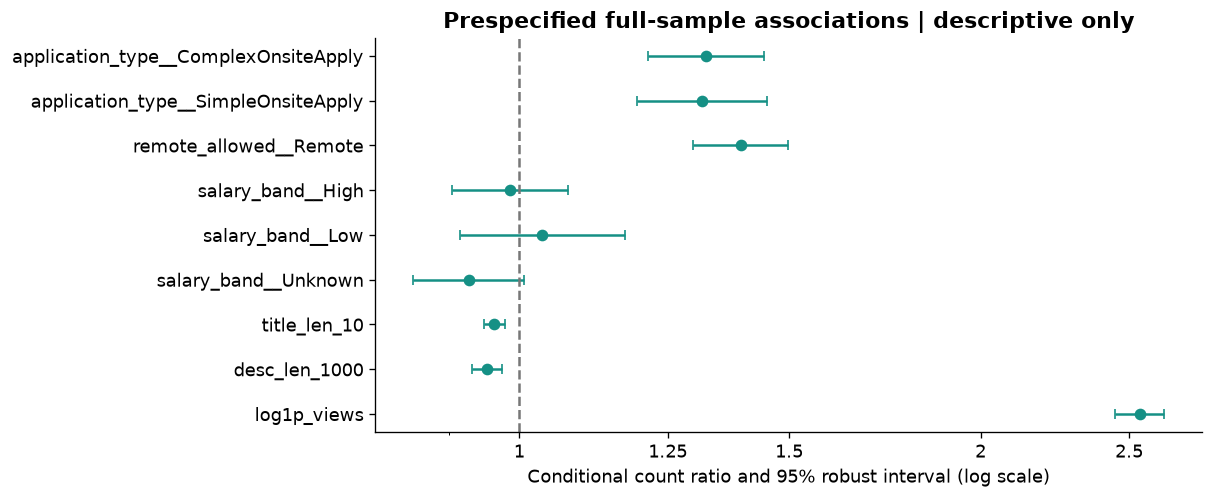

In [9]:
named_features = coefficients.feature.str.startswith(('application_type__', 'remote_allowed__', 'salary_band__'))
named_features |= coefficients.feature.isin(['log1p_views', 'title_len_10', 'desc_len_1000'])
selected = coefficients.loc[named_features].copy()
display(selected[['feature', 'irr', 'ci_lower', 'ci_upper', 'unit', 'covariance_type']].round(4))
drawable = selected[np.isfinite(selected.ci_lower) & np.isfinite(selected.ci_upper)
                    & selected.ci_lower.gt(0) & np.isfinite(selected.irr)]
singleton = drawable.feature.str.startswith('application_type__') & drawable.feature.str.endswith('__Other__')
drawable = drawable.loc[~singleton]
if len(drawable):
    fig, ax = plt.subplots(figsize=(10, max(4, len(drawable) * .45)), layout='constrained')
    ax.errorbar(drawable.irr, np.arange(len(drawable)),
                xerr=np.vstack([drawable.irr - drawable.ci_lower, drawable.ci_upper - drawable.irr]),
                fmt='o', capsize=3, color='#159085')
    ax.set_yticks(np.arange(len(drawable)), drawable.feature)
    ax.set_xscale('log')
    ax.xaxis.set_major_locator(FixedLocator([.5, .75, 1, 1.25, 1.5, 2, 2.5, 3, 4]))
    ax.xaxis.set_major_formatter(FuncFormatter(lambda value, position: f'{value:g}'))
    ax.xaxis.set_minor_formatter(NullFormatter())
    ax.axvline(1, color='#777777', linestyle='--')
    ax.set(xlabel='Conditional count ratio and 95% robust interval (log scale)',
           title='Prespecified full-sample associations | descriptive only')
    ax.invert_yaxis()
    plt.show()
else:
    print('No finite intervals for the selected features; see the full coefficient table.')

### 10. Inspect model reliance
XGBoost gain shares summarize how the fitted full-sample model uses features.
They are not estimates of how changing a job advertisement changes applications.
SVD components describe learned text directions, not fixed causal topics.

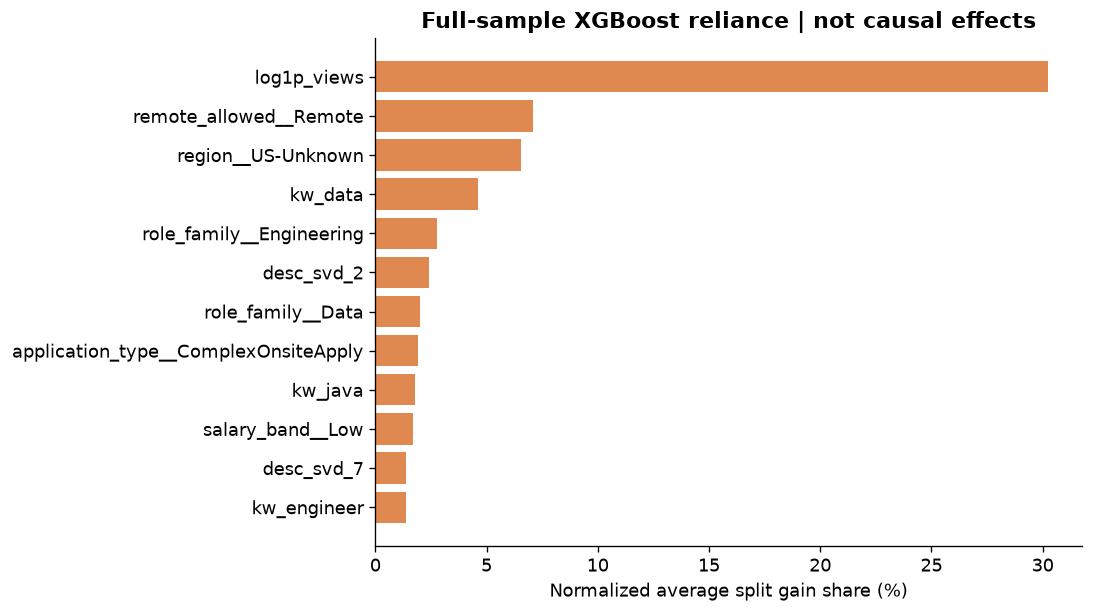

In [10]:
top_features = importance.nlargest(12, 'gain_share').sort_values('gain_share')
fig, ax = plt.subplots(figsize=(9, 5), layout='constrained')
ax.barh(top_features.feature, 100 * top_features.gain_share, color='#df8850')
ax.set(xlabel='Normalized average split gain share (%)',
       title='Full-sample XGBoost reliance | not causal effects')
plt.show()

## Takeaways

The saved results answer a narrow, reproducible question: how the prespecified
models predict recorded positive application counts for held-out postings with
observed views. Differences among models should be read with their pooled
error metrics, calibration and sensitivity comparisons, not a single winner.

The main correction is to recover trustworthy source rows and remove invalid
target/feature transformations before evaluating models on shared folds.
Target selection, unavailable zero counts, contemporaneous views, uncertain
observation duration and employer overlap remain limitations after repair.

## Reproduction and sources

The completed results are reviewed above without loading the 500 MB raw CSV.
To independently rerun the full workflow, install the project dependencies,
verify/download the pinned v13 CSV, and run the command printed below from
the repository root. The full-fit command is deliberately **not executed** by
this notebook. It will replace the repository's result artifacts if run.

- [Kaggle source, version 13](https://www.kaggle.com/datasets/arshkon/linkedin-job-postings/versions/13)
- [Source and licensing record](../docs/DATA_SOURCE.md)
- [Data acquisition and exclusions](../data/README.md)
- [Clean source transformations](../src/linkedin_analytics/data.py)
- [Training-only feature construction](../src/linkedin_analytics/features.py)
- [Model fitting and shared folds](../src/linkedin_analytics/modeling.py)
- [Independent results validator](../src/linkedin_analytics/validation.py)
- [Saved results](../results/)

In [11]:
# Commands for an independent rerun. They are displayed, not executed.
reproduction_commands = [
    'python -m pip install -e ".[download,notebook,test]"',
    'python scripts/download_data.py --output data/raw/postings.csv',
    'python -m linkedin_analytics --data data/raw/postings.csv --output results --config config.json',
    'python -m pytest',
    'python scripts/build_notebook.py --execute',
]
print('\n'.join(reproduction_commands))
# Optional manual execution after reviewing the command:
# import subprocess
# subprocess.run([sys.executable, '-m', 'linkedin_analytics', '--data', 'data/raw/postings.csv'], cwd=ROOT, check=True)

python -m pip install -e ".[download,notebook,test]"
python scripts/download_data.py --output data/raw/postings.csv
python -m linkedin_analytics --data data/raw/postings.csv --output results --config config.json
python -m pytest
python scripts/build_notebook.py --execute


In [12]:
display(pd.DataFrame.from_dict(metadata['versions'], orient='index', columns=['Completed-run version']))
print('Source CSV SHA-256:', audit['raw_dataset_sha256'])
print('Config SHA-256:', metadata['config_sha256'])
print('OOF CSV SHA-256:', validation['oof_sha256'])
print('Independent checks:', validation['status'])

,Completed-run version
numpy,2.4.6
pandas,3.0.6
scipy,1.17.1
scikit-learn,1.9.1
glum,3.4.1
xgboost,3.2.0
statsmodels,0.15.0
matplotlib,3.11.2
pyarrow,25.0.1
threadpoolctl,3.7.0


Source CSV SHA-256: de33f27c8d1b226014e0cede003404e9b0acb66db718671fda9b3e3538eca6ea
Config SHA-256: 7b495877a24927330247ee3541112752f338580f080c9945749f90c3d1cb9d28
OOF CSV SHA-256: 31a69fab51c4c5c391521ab69b1d0983acc92b50927e9aa251e94f34d159e6b4
Independent checks: passed
